In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

Classes: ['Basophil', 'Eosinophil', 'Lymphocyte', 'Monocyte', 'Neutrophil']
DualBranchNet(
  (local): LocalBranch(
    (gabor): GaborLayer(
      (conv): Conv2d(3, 16, kernel_size=(11, 11), stride=(1, 1), padding=(5, 5), bias=False)
    )
    (features): Sequential(
      (0): ReLU()
      (1): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (5): ReLU()
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (7): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (8): ReLU()
      (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (10): AdaptiveAvgPool2d(output_size=(1, 1))
    )
  )
  (global_branch): GlobalAttentionBranch(
    (stage1): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3)

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


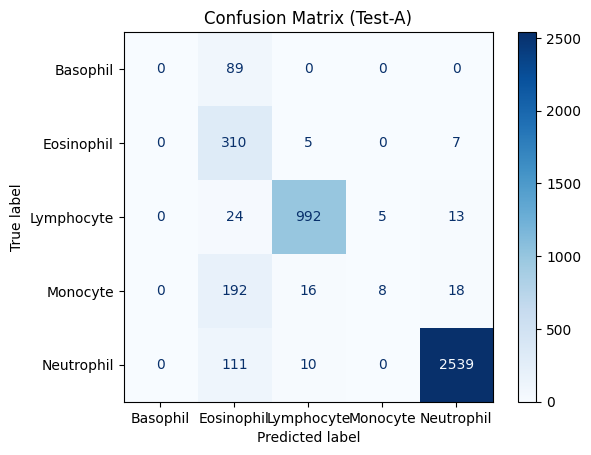


Test-B Accuracy: 0.7300613496932515


ValueError: Number of classes, 4, does not match size of target_names, 5. Try specifying the labels parameter

In [1]:
# ============================================================
# Dual-Branch: Gabor CNN + CNN with Shifted Window Attention
# Choquet Fusion (Minkowski Distance)
# PBC Leukocyte 5-Class Classification
# ============================================================

import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# -------------------------------------------------------------
# 1. Config & Seed
# -------------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 🔴 CHANGE THIS TO YOUR ACTUAL KAGGLE PATH
DATA_DIR = "/kaggle/input/white-blood-cells-dataset"  

BATCH_SIZE = 32
IMG_SIZE = 224          # These images are high-resolution
EPOCHS = 30
LR = 1e-4
NUM_CLASSES = 5        # Basophil, Eosinophil, Lymphocyte, Monocyte, Neutrophil

# -------------------------------------------------------------
# 2. Transforms
# -------------------------------------------------------------
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5])
])

val_test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5])
])

# -------------------------------------------------------------
# 3. Dataset Loading (According to Your Datacard)
# -------------------------------------------------------------
train_dir = os.path.join(DATA_DIR, "Train")
testA_dir = os.path.join(DATA_DIR, "Test-A")
testB_dir = os.path.join(DATA_DIR, "Test-B")

train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
testA_dataset = datasets.ImageFolder(testA_dir, transform=val_test_transform)
testB_dataset = datasets.ImageFolder(testB_dir, transform=val_test_transform)

# Split Train into Train/Val
val_ratio = 0.2
num_train = len(train_dataset)
num_val = int(val_ratio * num_train)
num_train2 = num_train - num_val

train_dataset, val_dataset = torch.utils.data.random_split(
    train_dataset, [num_train2, num_val]
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
testA_loader = DataLoader(testA_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
testB_loader = DataLoader(testB_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

class_names = train_dataset.dataset.classes
print("Classes:", class_names)

# -------------------------------------------------------------
# 4. Gabor Filter Layer
# -------------------------------------------------------------
class GaborLayer(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=11):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size,
                              padding=kernel_size // 2, bias=False)
        self._init_gabor()

    def _init_gabor(self):
        for i in range(self.conv.weight.shape[0]):
            theta = np.random.uniform(0, np.pi)
            sigma = np.random.uniform(2, 5)
            lamda = np.random.uniform(6, 10)
            gamma = 0.5
            kernel = self._gabor_kernel(11, sigma, theta, lamda, gamma)
            for c in range(3):
                self.conv.weight.data[i, c] = torch.tensor(kernel)

    def _gabor_kernel(self, ksize, sigma, theta, lamda, gamma):
        ax = np.linspace(-(ksize // 2), ksize // 2, ksize)
        xx, yy = np.meshgrid(ax, ax)
        x = xx * np.cos(theta) + yy * np.sin(theta)
        y = -xx * np.sin(theta) + yy * np.cos(theta)
        gb = np.exp(-(x**2 + gamma**2 * y**2) / (2 * sigma**2)) \
             * np.cos(2 * np.pi * x / lamda)
        return gb

    def forward(self, x):
        return self.conv(x)

# -------------------------------------------------------------
# 5. Local Branch
# -------------------------------------------------------------
class LocalBranch(nn.Module):
    def __init__(self):
        super().__init__()
        self.gabor = GaborLayer(3, 16)

        self.features = nn.Sequential(
            nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),               # 224 -> 112

            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),               # 112 -> 56

            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),               # 56 -> 28

            nn.AdaptiveAvgPool2d((1, 1))
        )

    def forward(self, x):
        x = self.gabor(x)
        x = self.features(x)
        x = x.view(x.size(0), -1)   # [B, 128]
        return x

# -------------------------------------------------------------
# 6. Window MSA (for 56x56 or 28x28 safely divisible by 7)
# -------------------------------------------------------------
class WindowMSA(nn.Module):
    def __init__(self, dim, window_size=7, num_heads=4):
        super().__init__()
        self.dim = dim
        self.window_size = window_size
        self.num_heads = num_heads
        self.scale = (dim // num_heads) ** -0.5

        self.qkv = nn.Linear(dim, dim * 3)
        self.proj = nn.Linear(dim, dim)

    def forward(self, x):
        B, H, W, C = x.shape
        ws = self.window_size

        x = x.view(B, H // ws, ws, W // ws, ws, C)
        x = x.permute(0, 1, 3, 2, 4, 5).contiguous()
        x = x.view(-1, ws * ws, C)

        qkv = self.qkv(x).reshape(x.size(0), x.size(1), 3, self.num_heads, C // self.num_heads)
        q, k, v = qkv.unbind(dim=2)

        q = q.transpose(1, 2)
        k = k.transpose(1, 2)
        v = v.transpose(1, 2)

        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = attn.softmax(dim=-1)

        out = attn @ v
        out = out.transpose(1, 2).reshape(x.size(0), x.size(1), C)
        out = self.proj(out)

        out = out.view(B, H // ws, W // ws, ws, ws, C)
        out = out.permute(0, 1, 3, 2, 4, 5).contiguous()
        out = out.view(B, H, W, C)

        return out

# -------------------------------------------------------------
# 7. Shifted Window Block
# -------------------------------------------------------------
class ShiftedWindowBlock(nn.Module):
    def __init__(self, dim, window_size=7, num_heads=4, shift_size=3):
        super().__init__()
        self.window_size = window_size
        self.shift_size = shift_size

        self.norm1 = nn.LayerNorm(dim)
        self.attn = WindowMSA(dim, window_size, num_heads)

        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * 4),
            nn.GELU(),
            nn.Linear(dim * 4, dim)
        )

    def forward(self, x):
        B, C, H, W = x.shape
        x = x.permute(0, 2, 3, 1)

        if self.shift_size > 0:
            x = torch.roll(x, shifts=(-self.shift_size, -self.shift_size), dims=(1, 2))

        x = x + self.attn(self.norm1(x))

        if self.shift_size > 0:
            x = torch.roll(x, shifts=(self.shift_size, self.shift_size), dims=(1, 2))

        x = x + self.mlp(self.norm2(x))
        x = x.permute(0, 3, 1, 2)
        return x

# -------------------------------------------------------------
# 8. Global Branch
# -------------------------------------------------------------
class GlobalAttentionBranch(nn.Module):
    def __init__(self):
        super().__init__()

        self.stage1 = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)   # 224 -> 112
        )

        self.stage2 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)   # 112 -> 56
        )

        # Attention on 56x56 (56 % 7 == 0)
        self.attn1 = ShiftedWindowBlock(128, window_size=7, num_heads=4, shift_size=0)
        self.attn2 = ShiftedWindowBlock(128, window_size=7, num_heads=4, shift_size=3)

        self.stage3 = nn.MaxPool2d(2)  # 56 -> 28

        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.proj = nn.Sequential(
            nn.Linear(128, 256),
            nn.ReLU()
        )

    def forward(self, x):
        x = self.stage1(x)     # 112x112
        x = self.stage2(x)     # 56x56

        x = self.attn1(x)
        x = self.attn2(x)

        x = self.stage3(x)    # 28x28

        x = self.global_pool(x)
        x = x.view(x.size(0), -1)

        z = self.proj(x)
        return z

# -------------------------------------------------------------
# 9. Choquet Fusion
# -------------------------------------------------------------
class ChoquetFusion(nn.Module):
    def __init__(self, dim1, dim2, out_dim=128, p=2):
        super().__init__()
        self.fc1 = nn.Linear(dim1, out_dim)
        self.fc2 = nn.Linear(dim2, out_dim)
        self.p = p

    def forward(self, f1, f2):
        z1 = self.fc1(f1)
        z2 = self.fc2(f2)

        d = torch.pow(torch.abs(z1 - z2), self.p).sum(dim=1, keepdim=True)
        fused = (z1 + z2) / (1.0 + d)
        return fused

# -------------------------------------------------------------
# 10. Dual Branch Network
# -------------------------------------------------------------
class DualBranchNet(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()

        self.local = LocalBranch()                 # [B, 128]
        self.global_branch = GlobalAttentionBranch()  # [B, 256]

        self.fusion = ChoquetFusion(128, 256, 128, p=2)
        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x):
        f_local = self.local(x)
        f_global = self.global_branch(x)

        fused = self.fusion(f_local, f_global)
        out = self.classifier(fused)
        return out

model = DualBranchNet(num_classes=NUM_CLASSES).to(device)
print(model)

# -------------------------------------------------------------
# 11. Loss & Optimizer
# -------------------------------------------------------------
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LR)

# -------------------------------------------------------------
# 12. Training & Validation Loop
# -------------------------------------------------------------
for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    preds_all, labels_all = [], []

    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        preds = torch.argmax(outputs, 1)

        preds_all.extend(preds.cpu().numpy())
        labels_all.extend(labels.cpu().numpy())

    train_loss = running_loss / len(train_loader)
    train_acc = accuracy_score(labels_all, preds_all)

    # Validation
    model.eval()
    preds_all, labels_all = [], []
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            preds = torch.argmax(outputs, 1)

            preds_all.extend(preds.cpu().numpy())
            labels_all.extend(labels.cpu().numpy())

    val_acc = accuracy_score(labels_all, preds_all)

    print(f"Epoch {epoch+1}/{EPOCHS} | "
          f"Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}")

# -------------------------------------------------------------
# 13. Testing on Test-A and Test-B Separately
# -------------------------------------------------------------
def evaluate(loader, name):
    model.eval()
    all_preds, all_labels = [], []

    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            preds = torch.argmax(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    print(f"\n{name} Accuracy:", acc)
    print(classification_report(all_labels, all_preds, target_names=class_names))

    cm = confusion_matrix(all_labels, all_preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(cmap=plt.cm.Blues)
    plt.title(f"Confusion Matrix ({name})")
    plt.show()

evaluate(testA_loader, "Test-A")
evaluate(testB_loader, "Test-B")


In [1]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import random
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score

# -------------------------------------------------------------
# 1. Global Configuration
# -------------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# 🔴 Update this path to your specific dataset location
DATA_DIR = "/kaggle/input/white-blood-cells-dataset" 

IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 20
LR = 1e-4
NUM_CLASSES = 5

# -------------------------------------------------------------
# 2. Data Pipeline
# -------------------------------------------------------------
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

val_test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

# Load Datasets
full_train_ds = datasets.ImageFolder(os.path.join(DATA_DIR, "Train"), transform=train_transform)
testA_ds = datasets.ImageFolder(os.path.join(DATA_DIR, "Test-A"), transform=val_test_transform)
testB_ds = datasets.ImageFolder(os.path.join(DATA_DIR, "Test-B"), transform=val_test_transform)

# 80/20 Train/Val Split
n_val = int(len(full_train_ds) * 0.2)
n_train = len(full_train_ds) - n_val
train_ds, val_ds = random_split(full_train_ds, [n_train, n_val])

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
testA_loader = DataLoader(testA_ds, batch_size=BATCH_SIZE, shuffle=False)
testB_loader = DataLoader(testB_ds, batch_size=BATCH_SIZE, shuffle=False)

# -------------------------------------------------------------
# 3. Local & Global Branches
# -------------------------------------------------------------
class GaborLayer(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=11):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size, padding=kernel_size//2, bias=False)
        self._init_gabor()

    def _init_gabor(self):
        for i in range(self.conv.weight.shape[0]):
            theta, sigma, lamda, gamma = np.random.uniform(0, np.pi), np.random.uniform(2, 5), \
                                         np.random.uniform(6, 10), 0.5
            ax = np.linspace(-(11//2), 11//2, 11)
            xx, yy = np.meshgrid(ax, ax)
            x = xx * np.cos(theta) + yy * np.sin(theta)
            y = -xx * np.sin(theta) + yy * np.cos(theta)
            gb = np.exp(-(x**2 + gamma**2 * y**2) / (2 * sigma**2)) * np.cos(2 * np.pi * x / lamda)
            for c in range(3): self.conv.weight.data[i, c] = torch.tensor(gb)

    def forward(self, x): return self.conv(x)

class LocalBranch(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            GaborLayer(3, 16), nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), # 112
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), # 56
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), # 28
            nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten()
        )
    def forward(self, x): return self.net(x)

class WindowMSA(nn.Module):
    def __init__(self, dim, window_size=7, num_heads=4):
        super().__init__()
        self.dim, self.ws, self.nh = dim, window_size, num_heads
        self.scale = (dim // num_heads) ** -0.5
        self.qkv = nn.Linear(dim, dim * 3)
        self.proj = nn.Linear(dim, dim)

    def forward(self, x):
        B, H, W, C = x.shape
        x = x.view(B, H // self.ws, self.ws, W // self.ws, self.ws, C).permute(0, 1, 3, 2, 4, 5).reshape(-1, self.ws*self.ws, C)
        qkv = self.qkv(x).reshape(x.shape[0], x.shape[1], 3, self.nh, C // self.nh).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = (attn.softmax(dim=-1) @ v).transpose(1, 2).reshape(-1, self.ws*self.ws, C)
        out = self.proj(attn).view(B, H // self.ws, W // self.ws, self.ws, self.ws, C).permute(0, 1, 3, 2, 4, 5).reshape(B, H, W, C)
        return out

class ShiftedWindowBlock(nn.Module):
    def __init__(self, dim, window_size=7, num_heads=4, shift_size=0):
        super().__init__()
        self.shift, self.ws = shift_size, window_size
        self.norm1 = nn.LayerNorm(dim)
        self.attn = WindowMSA(dim, window_size, num_heads)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(nn.Linear(dim, dim*4), nn.GELU(), nn.Linear(dim*4, dim))

    def forward(self, x):
        x = x.permute(0, 2, 3, 1)
        if self.shift > 0: x = torch.roll(x, shifts=(-self.shift, -self.shift), dims=(1, 2))
        x = x + self.attn(self.norm1(x))
        if self.shift > 0: x = torch.roll(x, shifts=(self.shift, self.shift), dims=(1, 2))
        return (x + self.mlp(self.norm2(x))).permute(0, 3, 1, 2)

class GlobalBranch(nn.Module):
    def __init__(self):
        super().__init__()
        self.stage1 = nn.Sequential(nn.Conv2d(3, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)) # 112
        self.stage2 = nn.Sequential(nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)) # 56
        self.attn = nn.Sequential(
            ShiftedWindowBlock(128, 7, 4, 0),
            ShiftedWindowBlock(128, 7, 4, 3)
        )
        self.head = nn.Sequential(nn.MaxPool2d(2), nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten(), nn.Linear(128, 256), nn.ReLU())
    def forward(self, x): return self.head(self.attn(self.stage2(self.stage1(x))))

# -------------------------------------------------------------
# 4. Fusion Variants
# -------------------------------------------------------------
class BaseFusion(nn.Module):
    def __init__(self, d1=128, d2=256, d_out=128):
        super().__init__()
        self.p1, self.p2 = nn.Linear(d1, d_out), nn.Linear(d2, d_out)

class ConcatFusion(BaseFusion):
    def forward(self, f1, f2): return torch.cat([self.p1(f1), self.p2(f2)], dim=1)

class WeightedAvgFusion(BaseFusion):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.w = nn.Parameter(torch.ones(2))
    def forward(self, f1, f2):
        sw = torch.softmax(self.w, dim=0)
        return sw[0] * self.p1(f1) + sw[1] * self.p2(f2)

class ParsevalFusion(BaseFusion):
    def forward(self, f1, f2):
        z1, z2 = self.p1(f1), self.p2(f2)
        eta = (2 * torch.sum(z1 * z2, 1)) / (torch.sum(z1**2, 1) + torch.sum(z2**2, 1) + 1e-8)
        return ((1 + eta)/2).unsqueeze(1) * (z1 + z2)

class FullChoquetFusion(BaseFusion):
    def forward(self, f1, f2):
        z1, z2 = self.p1(f1), self.p2(f2)
        d3 = torch.pow(torch.sum(torch.abs(z1 - z2)**3, 1), 1/3)
        alpha = 1 / (1 + d3 + 1e-8)
        eta = (2 * torch.sum(z1 * z2, 1)) / (torch.sum(z1**2, 1) + torch.sum(z2**2, 1) + 1e-8)
        return (((1 + eta)/2) * alpha).unsqueeze(1) * (z1 + z2)

# -------------------------------------------------------------
# 5. Master Architecture & Engine
# -------------------------------------------------------------
class DualBranchNet(nn.Module):
    def __init__(self, f_type='choquet'):
        super().__init__()
        self.local, self.gb = LocalBranch(), GlobalBranch()
        f_map = {'concat': (ConcatFusion, 256), 'weight': (WeightedAvgFusion, 128), 
                 'parseval': (ParsevalFusion, 128), 'choquet': (FullChoquetFusion, 128)}
        f_cls, c_in = f_map[f_type]
        self.fusion, self.classifier = f_cls(), nn.Linear(c_in, NUM_CLASSES)
    def forward(self, x): return self.classifier(self.fusion(self.local(x), self.gb(x)))

def train_eval(variant):
    print(f"\n>>> Starting: {variant.upper()}")
    model = DualBranchNet(variant).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=LR)
    criterion = nn.CrossEntropyLoss()

    for epoch in range(1, EPOCHS + 1):
        model.train()
        tp, tl = [], []
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            out = model(imgs)
            loss = criterion(out, labels)
            loss.backward()
            optimizer.step()
            tp.extend(torch.argmax(out, 1).cpu().numpy())
            tl.extend(labels.cpu().numpy())
        
        # Validation
        model.eval()
        vp, vl = [], []
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                out = model(imgs)
                vp.extend(torch.argmax(out, 1).cpu().numpy())
                vl.extend(labels.cpu().numpy())
        print(f"Epoch [{epoch:02d}/{EPOCHS}] Train Acc: {accuracy_score(tl, tp):.4f} Val Acc: {accuracy_score(vl, vp):.4f}")

    # Final Test
    def get_acc(loader):
        model.eval()
        p, l = [], []
        with torch.no_grad():
            for imgs, labels in loader:
                imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
                out = model(imgs)
                p.extend(torch.argmax(out, 1).cpu().numpy())
                l.extend(labels.cpu().numpy())
        return accuracy_score(l, p)

    accA, accB = get_acc(testA_loader), get_acc(testB_loader)
    print(f"--- Final {variant.upper()} -> Test-A: {accA:.4f} | Test-B: {accB:.4f} ---")

if __name__ == "__main__":
    for v in ['concat', 'weight', 'parseval', 'choquet']: train_eval(v)


>>> Starting: CONCAT
Epoch [01/20] Train Acc: 0.6127 Val Acc: 0.6192
Epoch [02/20] Train Acc: 0.7549 Val Acc: 0.8482
Epoch [03/20] Train Acc: 0.8619 Val Acc: 0.8904
Epoch [04/20] Train Acc: 0.8957 Val Acc: 0.9115
Epoch [05/20] Train Acc: 0.9091 Val Acc: 0.9312
Epoch [06/20] Train Acc: 0.9244 Val Acc: 0.9199
Epoch [07/20] Train Acc: 0.9287 Val Acc: 0.9287
Epoch [08/20] Train Acc: 0.9405 Val Acc: 0.9430
Epoch [09/20] Train Acc: 0.9399 Val Acc: 0.9435
Epoch [10/20] Train Acc: 0.9509 Val Acc: 0.9474
Epoch [11/20] Train Acc: 0.9527 Val Acc: 0.9572
Epoch [12/20] Train Acc: 0.9585 Val Acc: 0.9617
Epoch [13/20] Train Acc: 0.9634 Val Acc: 0.9681
Epoch [14/20] Train Acc: 0.9638 Val Acc: 0.9587
Epoch [15/20] Train Acc: 0.9633 Val Acc: 0.9607
Epoch [16/20] Train Acc: 0.9690 Val Acc: 0.9627
Epoch [17/20] Train Acc: 0.9684 Val Acc: 0.9563
Epoch [18/20] Train Acc: 0.9726 Val Acc: 0.9636
Epoch [19/20] Train Acc: 0.9704 Val Acc: 0.9725
Epoch [20/20] Train Acc: 0.9719 Val Acc: 0.9671
--- Final CONCAT -

Classes: ['Basophil', 'Eosinophil', 'Lymphocyte', 'Monocyte', 'Neutrophil']
DualBranchNet(
  (local): LocalBranch(
    (gabor): GaborLayer(
      (conv): Conv2d(3, 16, kernel_size=(11, 11), stride=(1, 1), padding=(5, 5), bias=False)
    )
    (features): Sequential(
      (0): ReLU()
      (1): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (5): ReLU()
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (7): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (8): ReLU()
      (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (10): AdaptiveAvgPool2d(output_size=(1, 1))
    )
  )
  (global_branch): GlobalAttentionBranch(
    (stage1): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3)

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


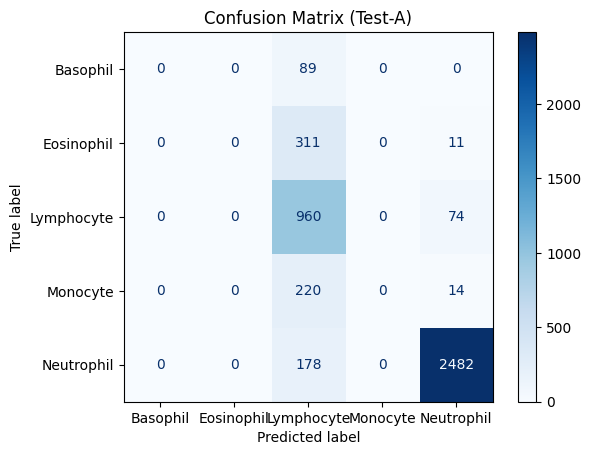


Test-B Accuracy: 0.0


ValueError: Number of classes, 4, does not match size of target_names, 5. Try specifying the labels parameter

In [2]:
# ============================================================
# Dual-Branch: Gabor CNN + CNN with Shifted Window Attention
# Choquet Fusion (Minkowski Distance)
# PBC Leukocyte 5-Class Classification
# ============================================================

import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# -------------------------------------------------------------
# 1. Config & Seed
# -------------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 🔴 CHANGE THIS TO YOUR ACTUAL KAGGLE PATH
DATA_DIR = "/kaggle/input/white-blood-cells-dataset"  

BATCH_SIZE = 32
IMG_SIZE = 224          # These images are high-resolution
EPOCHS = 5
LR = 1e-4
NUM_CLASSES = 5        # Basophil, Eosinophil, Lymphocyte, Monocyte, Neutrophil

# -------------------------------------------------------------
# 2. Transforms
# -------------------------------------------------------------
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5])
])

val_test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5])
])

# -------------------------------------------------------------
# 3. Dataset Loading (According to Your Datacard)
# -------------------------------------------------------------
train_dir = os.path.join(DATA_DIR, "Train")
testA_dir = os.path.join(DATA_DIR, "Test-A")
testB_dir = os.path.join(DATA_DIR, "Test-B")

train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
testA_dataset = datasets.ImageFolder(testA_dir, transform=val_test_transform)
testB_dataset = datasets.ImageFolder(testB_dir, transform=val_test_transform)

# Split Train into Train/Val
val_ratio = 0.2
num_train = len(train_dataset)
num_val = int(val_ratio * num_train)
num_train2 = num_train - num_val

train_dataset, val_dataset = torch.utils.data.random_split(
    train_dataset, [num_train2, num_val]
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
testA_loader = DataLoader(testA_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
testB_loader = DataLoader(testB_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

class_names = train_dataset.dataset.classes
print("Classes:", class_names)

# -------------------------------------------------------------
# 4. Gabor Filter Layer
# -------------------------------------------------------------
class GaborLayer(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=11):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size,
                              padding=kernel_size // 2, bias=False)
        self._init_gabor()

    def _init_gabor(self):
        for i in range(self.conv.weight.shape[0]):
            theta = np.random.uniform(0, np.pi)
            sigma = np.random.uniform(2, 5)
            lamda = np.random.uniform(6, 10)
            gamma = 0.5
            kernel = self._gabor_kernel(11, sigma, theta, lamda, gamma)
            for c in range(3):
                self.conv.weight.data[i, c] = torch.tensor(kernel)

    def _gabor_kernel(self, ksize, sigma, theta, lamda, gamma):
        ax = np.linspace(-(ksize // 2), ksize // 2, ksize)
        xx, yy = np.meshgrid(ax, ax)
        x = xx * np.cos(theta) + yy * np.sin(theta)
        y = -xx * np.sin(theta) + yy * np.cos(theta)
        gb = np.exp(-(x**2 + gamma**2 * y**2) / (2 * sigma**2)) \
             * np.cos(2 * np.pi * x / lamda)
        return gb

    def forward(self, x):
        return self.conv(x)

# -------------------------------------------------------------
# 5. Local Branch
# -------------------------------------------------------------
class LocalBranch(nn.Module):
    def __init__(self):
        super().__init__()
        self.gabor = GaborLayer(3, 16)

        self.features = nn.Sequential(
            nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),               # 224 -> 112

            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),               # 112 -> 56

            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),               # 56 -> 28

            nn.AdaptiveAvgPool2d((1, 1))
        )

    def forward(self, x):
        x = self.gabor(x)
        x = self.features(x)
        x = x.view(x.size(0), -1)   # [B, 128]
        return x

# -------------------------------------------------------------
# 6. Window MSA (for 56x56 or 28x28 safely divisible by 7)
# -------------------------------------------------------------
class WindowMSA(nn.Module):
    def __init__(self, dim, window_size=7, num_heads=4):
        super().__init__()
        self.dim = dim
        self.window_size = window_size
        self.num_heads = num_heads
        self.scale = (dim // num_heads) ** -0.5

        self.qkv = nn.Linear(dim, dim * 3)
        self.proj = nn.Linear(dim, dim)

    def forward(self, x):
        B, H, W, C = x.shape
        ws = self.window_size

        x = x.view(B, H // ws, ws, W // ws, ws, C)
        x = x.permute(0, 1, 3, 2, 4, 5).contiguous()
        x = x.view(-1, ws * ws, C)

        qkv = self.qkv(x).reshape(x.size(0), x.size(1), 3, self.num_heads, C // self.num_heads)
        q, k, v = qkv.unbind(dim=2)

        q = q.transpose(1, 2)
        k = k.transpose(1, 2)
        v = v.transpose(1, 2)

        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = attn.softmax(dim=-1)

        out = attn @ v
        out = out.transpose(1, 2).reshape(x.size(0), x.size(1), C)
        out = self.proj(out)

        out = out.view(B, H // ws, W // ws, ws, ws, C)
        out = out.permute(0, 1, 3, 2, 4, 5).contiguous()
        out = out.view(B, H, W, C)

        return out

# -------------------------------------------------------------
# 7. Shifted Window Block
# -------------------------------------------------------------
class ShiftedWindowBlock(nn.Module):
    def __init__(self, dim, window_size=7, num_heads=4, shift_size=3):
        super().__init__()
        self.window_size = window_size
        self.shift_size = shift_size

        self.norm1 = nn.LayerNorm(dim)
        self.attn = WindowMSA(dim, window_size, num_heads)

        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * 4),
            nn.GELU(),
            nn.Linear(dim * 4, dim)
        )

    def forward(self, x):
        B, C, H, W = x.shape
        x = x.permute(0, 2, 3, 1)

        if self.shift_size > 0:
            x = torch.roll(x, shifts=(-self.shift_size, -self.shift_size), dims=(1, 2))

        x = x + self.attn(self.norm1(x))

        if self.shift_size > 0:
            x = torch.roll(x, shifts=(self.shift_size, self.shift_size), dims=(1, 2))

        x = x + self.mlp(self.norm2(x))
        x = x.permute(0, 3, 1, 2)
        return x

# -------------------------------------------------------------
# 8. Global Branch
# -------------------------------------------------------------
class GlobalAttentionBranch(nn.Module):
    def __init__(self):
        super().__init__()

        self.stage1 = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)   # 224 -> 112
        )

        self.stage2 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)   # 112 -> 56
        )

        # Attention on 56x56 (56 % 7 == 0)
        self.attn1 = ShiftedWindowBlock(128, window_size=7, num_heads=4, shift_size=0)
        self.attn2 = ShiftedWindowBlock(128, window_size=7, num_heads=4, shift_size=3)

        self.stage3 = nn.MaxPool2d(2)  # 56 -> 28

        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.proj = nn.Sequential(
            nn.Linear(128, 256),
            nn.ReLU()
        )

    def forward(self, x):
        x = self.stage1(x)     # 112x112
        x = self.stage2(x)     # 56x56

        x = self.attn1(x)
        x = self.attn2(x)

        x = self.stage3(x)    # 28x28

        x = self.global_pool(x)
        x = x.view(x.size(0), -1)

        z = self.proj(x)
        return z

# -------------------------------------------------------------
# 9. Choquet Fusion
# -------------------------------------------------------------
class ChoquetFusion(nn.Module):
    def __init__(self, dim1, dim2, out_dim=128, p=2):
        super().__init__()
        self.fc1 = nn.Linear(dim1, out_dim)
        self.fc2 = nn.Linear(dim2, out_dim)
        self.p = p

    def forward(self, f1, f2):
        z1 = self.fc1(f1)
        z2 = self.fc2(f2)

        d = torch.pow(torch.abs(z1 - z2), self.p).sum(dim=1, keepdim=True)
        fused = (z1 + z2) / (1.0 + d)
        return fused

# -------------------------------------------------------------
# 10. Dual Branch Network
# -------------------------------------------------------------
class DualBranchNet(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()

        self.local = LocalBranch()                 # [B, 128]
        self.global_branch = GlobalAttentionBranch()  # [B, 256]

        self.fusion = ChoquetFusion(128, 256, 128, p=2)
        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x):
        f_local = self.local(x)
        f_global = self.global_branch(x)

        fused = self.fusion(f_local, f_global)
        out = self.classifier(fused)
        return out

model = DualBranchNet(num_classes=NUM_CLASSES).to(device)
print(model)

# -------------------------------------------------------------
# 11. Loss & Optimizer
# -------------------------------------------------------------
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LR)

# -------------------------------------------------------------
# 12. Training & Validation Loop
# -------------------------------------------------------------
for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    preds_all, labels_all = [], []

    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        preds = torch.argmax(outputs, 1)

        preds_all.extend(preds.cpu().numpy())
        labels_all.extend(labels.cpu().numpy())

    train_loss = running_loss / len(train_loader)
    train_acc = accuracy_score(labels_all, preds_all)

    # Validation
    model.eval()
    preds_all, labels_all = [], []
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            preds = torch.argmax(outputs, 1)

            preds_all.extend(preds.cpu().numpy())
            labels_all.extend(labels.cpu().numpy())

    val_acc = accuracy_score(labels_all, preds_all)

    print(f"Epoch {epoch+1}/{EPOCHS} | "
          f"Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}")

# -------------------------------------------------------------
# 13. Testing on Test-A and Test-B Separately
# -------------------------------------------------------------
def evaluate(loader, name):
    model.eval()
    all_preds, all_labels = [], []

    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            preds = torch.argmax(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    print(f"\n{name} Accuracy:", acc)
    print(classification_report(all_labels, all_preds, target_names=class_names))

    cm = confusion_matrix(all_labels, all_preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(cmap=plt.cm.Blues)
    plt.title(f"Confusion Matrix ({name})")
    plt.show()

evaluate(testA_loader, "Test-A")
evaluate(testB_loader, "Test-B")


[*] Extracting features ...
    Local  : (4339, 128)
    Global : (4339, 256)
    Fused  : (4339, 128)
  Running t-SNE: Local Branch
(Gabor-CNN) ...


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


  Running t-SNE: Global Branch
(Shifted-Window Attn) ...


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


  Running t-SNE: Fused Features
(Choquet Fusion Output) ...


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


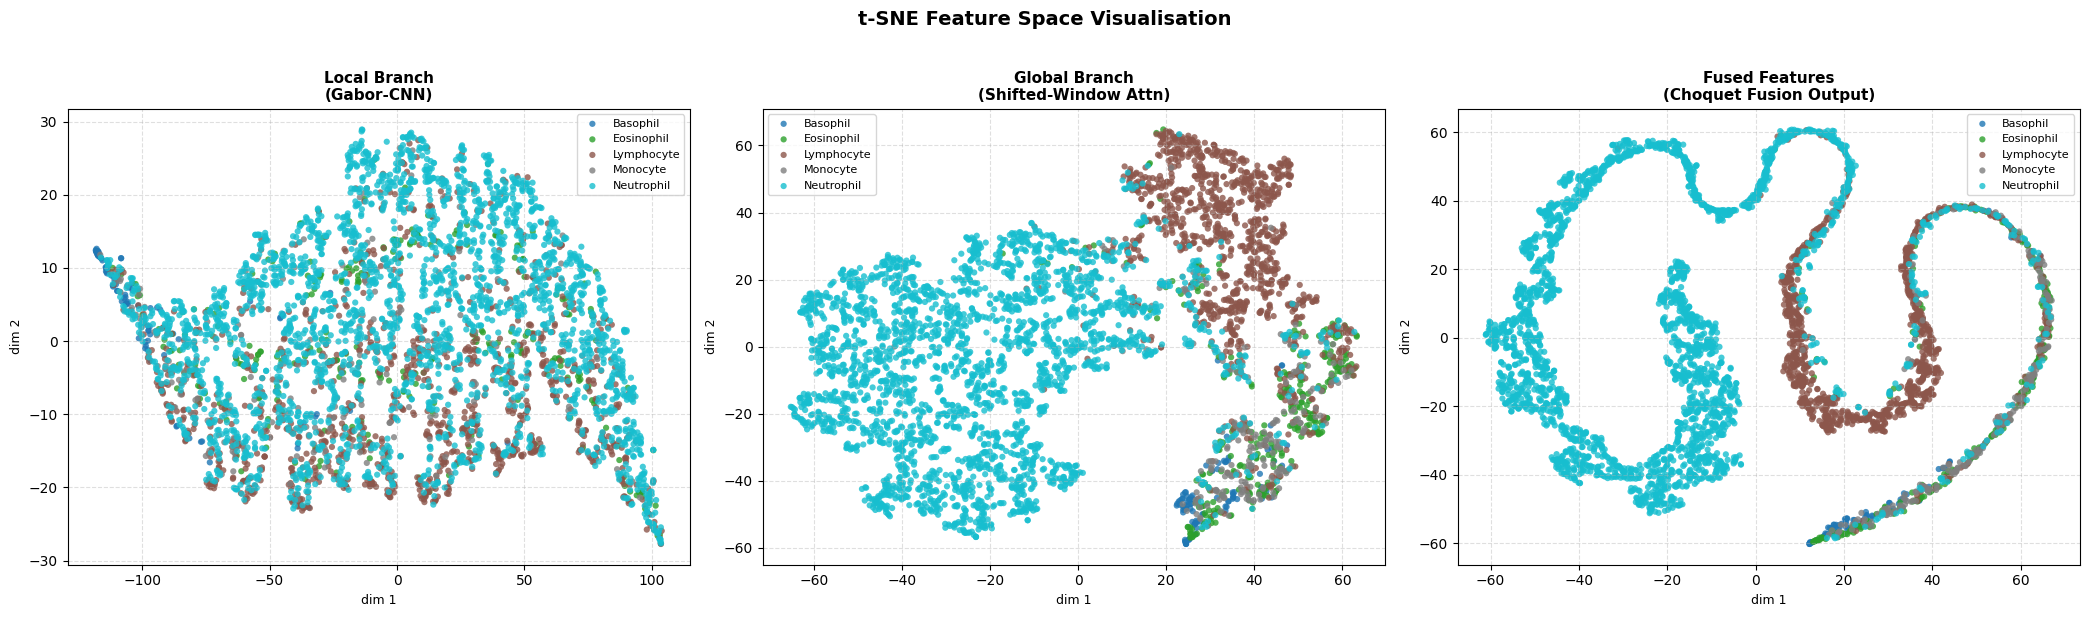

[✓] Saved → /kaggle/working/tsne_all_branches.png


In [3]:
# ============================================================
# t-SNE Plots: Local, Global, and Fused Branch Features
# Run this AFTER your training cell
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import torch

SEED = 42

# =============================================================
# STEP 1 — Extract Features from All Three Branches
# =============================================================

def extract_features(model, loader, device):
    model.eval()

    local_feats  = []
    global_feats = []
    fused_feats  = []
    all_labels   = []

    # Hook to capture fusion output
    fused_buffer = []
    def fused_hook(module, input, output):
        fused_buffer.append(output.detach().cpu().numpy())

    handle = model.fusion.register_forward_hook(fused_hook)

    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)

            lf = model.local(imgs).cpu().numpy()          # [B, 128]
            gf = model.global_branch(imgs).cpu().numpy()  # [B, 256]

            local_feats.append(lf)
            global_feats.append(gf)
            all_labels.extend(labels.numpy())

            _ = model(imgs)   # triggers the fusion hook

    handle.remove()

    return (
        np.vstack(local_feats),
        np.vstack(global_feats),
        np.vstack(fused_buffer),
        np.array(all_labels)
    )


# =============================================================
# STEP 2 — Plot t-SNE
# =============================================================

def plot_tsne(features, labels, class_names, title, ax, perplexity=30):
    print(f"  Running t-SNE: {title} ...")
    tsne = TSNE(n_components=2, perplexity=perplexity,
                n_iter=1000, random_state=SEED)
    emb  = tsne.fit_transform(features)

    colors = plt.cm.tab10(np.linspace(0, 1, len(class_names)))
    for idx, (cls_name, color) in enumerate(zip(class_names, colors)):
        mask = labels == idx
        ax.scatter(emb[mask, 0], emb[mask, 1],
                   label=cls_name, color=color,
                   s=20, alpha=0.8, edgecolors='none')

    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel("dim 1", fontsize=9)
    ax.set_ylabel("dim 2", fontsize=9)
    ax.legend(fontsize=8, loc='best')
    ax.grid(True, linestyle='--', alpha=0.4)


# =============================================================
# STEP 3 — Run Everything
# =============================================================

print("[*] Extracting features ...")
local_f, global_f, fused_f, labels = extract_features(model, testA_loader, device)
print(f"    Local  : {local_f.shape}")
print(f"    Global : {global_f.shape}")
print(f"    Fused  : {fused_f.shape}")

fig, axes = plt.subplots(1, 3, figsize=(21, 6))
fig.suptitle("t-SNE Feature Space Visualisation", fontsize=14, fontweight='bold', y=1.02)

plot_tsne(local_f,  labels, class_names, "Local Branch\n(Gabor-CNN)",              axes[0])
plot_tsne(global_f, labels, class_names, "Global Branch\n(Shifted-Window Attn)",   axes[1])
plot_tsne(fused_f,  labels, class_names, "Fused Features\n(Choquet Fusion Output)", axes[2])

plt.tight_layout()
plt.savefig("/kaggle/working/tsne_all_branches.png", dpi=150, bbox_inches='tight')
plt.show()
print("[✓] Saved → /kaggle/working/tsne_all_branches.png")

In [4]:
from IPython.display import FileLink
FileLink('/kaggle/working/tsne_all_branches.png')

/kaggle/working/tsne_all_branches.png

  Running t-SNE: Local Branch
(Gabor-CNN, dim=64) ...


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


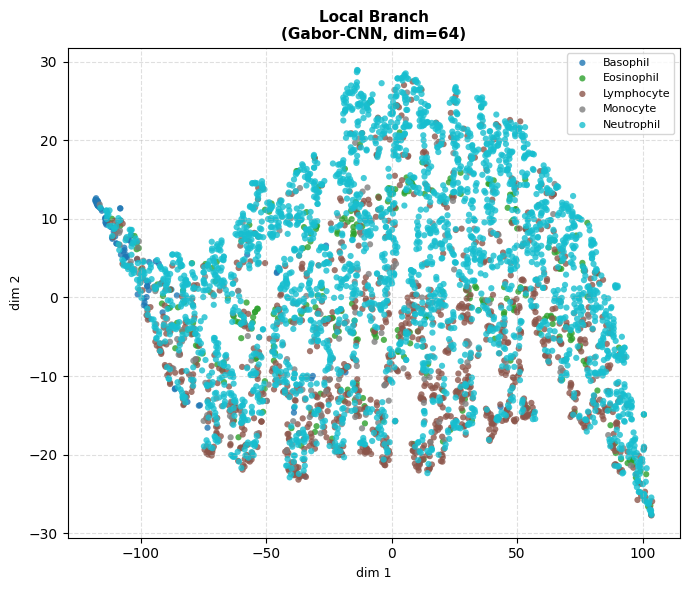

  Running t-SNE: Global Branch
(Shifted-Window Attn, dim=256) ...


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


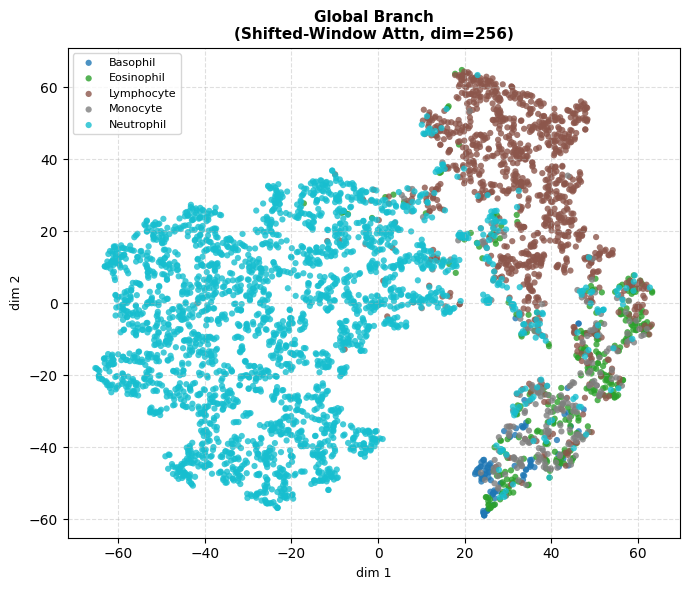

  Running t-SNE: Fused Features
(Choquet Fusion, dim=128) ...


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


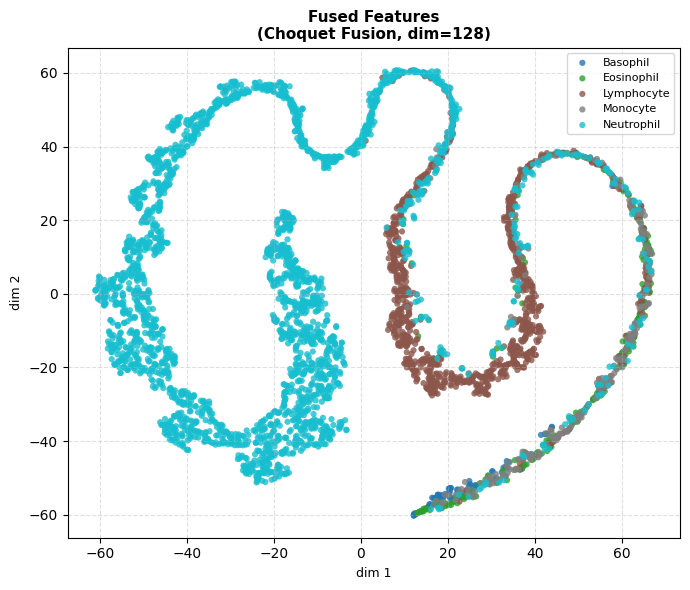

In [5]:
fig_local, ax1 = plt.subplots(figsize=(7, 6))
plot_tsne(local_f, labels, class_names, "Local Branch\n(Gabor-CNN, dim=64)", ax1)
plt.tight_layout()
plt.savefig("/kaggle/working/tsne_local_branch.png", dpi=150, bbox_inches='tight')
plt.show()

fig_global, ax2 = plt.subplots(figsize=(7, 6))
plot_tsne(global_f, labels, class_names, "Global Branch\n(Shifted-Window Attn, dim=256)", ax2)
plt.tight_layout()
plt.savefig("/kaggle/working/tsne_global_branch.png", dpi=150, bbox_inches='tight')
plt.show()

fig_fused, ax3 = plt.subplots(figsize=(7, 6))
plot_tsne(fused_f, labels, class_names, "Fused Features\n(Choquet Fusion, dim=128)", ax3)
plt.tight_layout()
plt.savefig("/kaggle/working/tsne_fused.png", dpi=150, bbox_inches='tight')
plt.show()

In [6]:
from IPython.display import FileLink, display
display(FileLink('/kaggle/working/tsne_local_branch.png'))
display(FileLink('/kaggle/working/tsne_global_branch.png'))
display(FileLink('/kaggle/working/tsne_fused.png'))

/kaggle/working/tsne_local_branch.png

/kaggle/working/tsne_global_branch.png

/kaggle/working/tsne_fused.png

Epoch 1 complete.
Epoch 2 complete.
Epoch 3 complete.
Epoch 4 complete.
Epoch 5 complete.


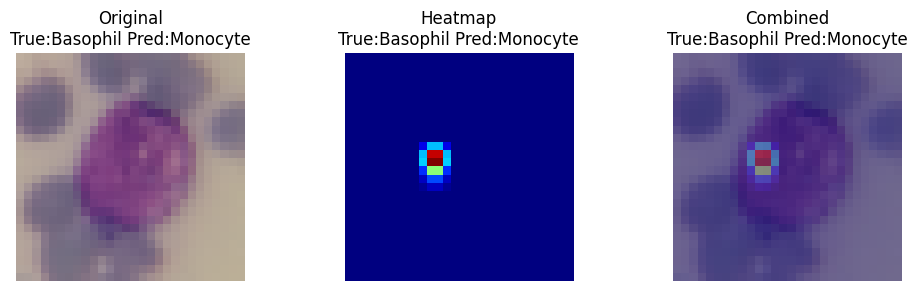

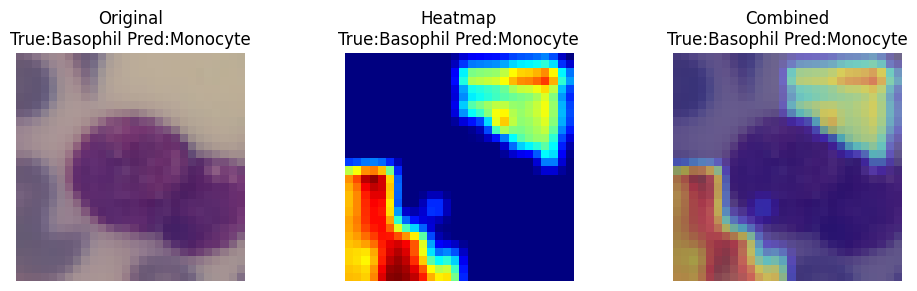

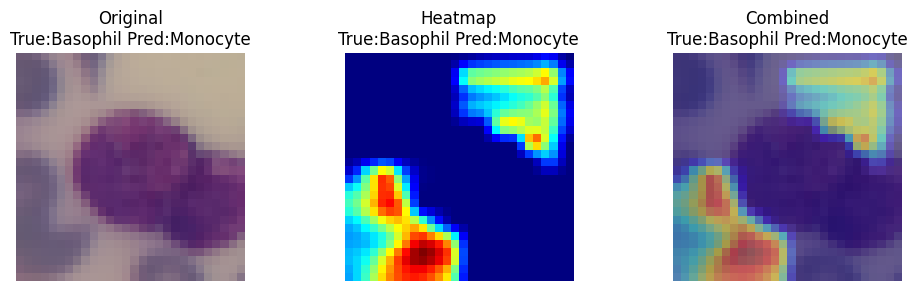

In [2]:
import os
import cv2

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# -------------------------------------------------------------
# 1. Config & Seed
# -------------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_DIR = "/kaggle/input/white-blood-cells-dataset"
BATCH_SIZE = 32
IMG_SIZE = 28
EPOCHS = 5
LR = 1e-3
NUM_CLASSES = 5

# -------------------------------------------------------------
# 2. Components (Gabor, Local, Global Branches)
# -------------------------------------------------------------
class GaborLayer(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=11):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size, padding=kernel_size//2, bias=False)
        self._init_gabor()

    def _init_gabor(self):
        for i in range(self.conv.weight.shape[0]):
            theta, sigma, lamda, gamma = np.random.uniform(0, np.pi), np.random.uniform(2, 5), \
                                         np.random.uniform(6, 10), 0.5
            ax = np.linspace(-(11//2), 11//2, 11)
            xx, yy = np.meshgrid(ax, ax)
            x = xx * np.cos(theta) + yy * np.sin(theta)
            y = -xx * np.sin(theta) + yy * np.cos(theta)
            gb = np.exp(-(x**2 + gamma**2 * y**2) / (2 * sigma**2)) * np.cos(2 * np.pi * x / lamda)
            for c in range(3): self.conv.weight.data[i, c] = torch.tensor(gb)

    def forward(self, x): return self.conv(x)

class LocalBranch(nn.Module):
    def __init__(self):
        super().__init__()
        self.gabor = GaborLayer(3, 16)
        self.features = nn.Sequential(
            nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU() # Target for Grad-CAM [B, 64, 14, 14]
        )
        self.pool = nn.AdaptiveAvgPool2d((1, 1))

    def forward(self, x):
        x = self.gabor(x)
        feat = self.features(x)
        out = self.pool(feat).view(feat.size(0), -1)
        return out, feat

class WindowMSA(nn.Module):
    def __init__(self, dim, window_size=7, num_heads=4):
        super().__init__()
        self.dim, self.ws, self.nh = dim, window_size, num_heads
        self.scale = (dim // num_heads) ** -0.5
        self.qkv = nn.Linear(dim, dim * 3)
        self.proj = nn.Linear(dim, dim)

    def forward(self, x):
        B, H, W, C = x.shape
        x = x.view(B, H // self.ws, self.ws, W // self.ws, self.ws, C).permute(0, 1, 3, 2, 4, 5).reshape(-1, self.ws*self.ws, C)
        qkv = self.qkv(x).reshape(x.shape[0], x.shape[1], 3, self.nh, C // self.nh).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = attn.softmax(dim=-1)
        out = (attn @ v).transpose(1, 2).reshape(-1, self.ws*self.ws, C)
        return self.proj(out).view(B, H // self.ws, W // self.ws, self.ws, self.ws, C).permute(0, 1, 3, 2, 4, 5).reshape(B, H, W, C)

class ShiftedWindowBlock(nn.Module):
    def __init__(self, dim, window_size=7, num_heads=4, shift_size=3):
        super().__init__()
        self.shift, self.ws = shift_size, window_size
        self.norm1 = nn.LayerNorm(dim)
        self.attn = WindowMSA(dim, window_size, num_heads)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(nn.Linear(dim, dim*4), nn.GELU(), nn.Linear(dim*4, dim))

    def forward(self, x):
        B, C, H, W = x.shape
        x = x.permute(0, 2, 3, 1)
        if self.shift > 0: x = torch.roll(x, shifts=(-self.shift, -self.shift), dims=(1, 2))
        x = x + self.attn(self.norm1(x))
        if self.shift > 0: x = torch.roll(x, shifts=(self.shift, self.shift), dims=(1, 2))
        x = x + self.mlp(self.norm2(x))
        return x.permute(0, 3, 1, 2)

class GlobalAttentionBranch(nn.Module):
    def __init__(self):
        super().__init__()
        self.stage1 = nn.Sequential(nn.Conv2d(3, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.stage2_conv = nn.Conv2d(64, 128, 3, padding=1)
        self.attn_block1 = ShiftedWindowBlock(dim=128, window_size=7, num_heads=4, shift_size=0)
        self.attn_block2 = ShiftedWindowBlock(dim=128, window_size=7, num_heads=4, shift_size=3)
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.proj = nn.Sequential(nn.Linear(128, 256), nn.ReLU())

    def forward(self, x):
        x = self.stage2_conv(self.stage1(x))
        x = self.attn_block1(x)
        feat = self.attn_block2(x) # Target for Grad-CAM [B, 128, 14, 14]
        out = self.pool(feat).view(feat.size(0), -1)
        return self.proj(out), feat

# -------------------------------------------------------------
# 3. Choquet Fusion & Network
# -------------------------------------------------------------
class ChoquetFusion(nn.Module):
    def __init__(self, dim1, dim2, out_dim=128, p=2):
        super().__init__()
        self.fc1, self.fc2, self.p = nn.Linear(dim1, out_dim), nn.Linear(dim2, out_dim), p
    def forward(self, f1, f2):
        z1, z2 = self.fc1(f1), self.fc2(f2)
        d = torch.pow(torch.abs(z1 - z2), self.p).sum(dim=1, keepdim=True)
        return (z1 + z2) / (1.0 + d)

class DualBranchNet(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()
        self.local = LocalBranch()
        self.global_branch = GlobalAttentionBranch()
        self.fusion = ChoquetFusion(64, 256, 128, p=2)
        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x):
        f_l, feat_l = self.local(x)
        f_g, feat_g = self.global_branch(x)
        fused = self.fusion(f_l, f_g)
        return self.classifier(fused)

# -------------------------------------------------------------
# 4. Grad-CAM Class
# -------------------------------------------------------------
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        self.target_layer.register_forward_hook(self.forward_hook)
        self.target_layer.register_full_backward_hook(self.backward_hook)

    def forward_hook(self, module, input, output):
        self.activations = output

    def backward_hook(self, module, grad_in, grad_out):
        self.gradients = grad_out[0]

    def __call__(self, input_tensor, class_idx=None):
        self.model.eval()
        output = self.model(input_tensor)
        if class_idx is None: class_idx = torch.argmax(output, dim=1).item()
        
        self.model.zero_grad()
        one_hot = torch.zeros_like(output)
        one_hot[0][class_idx] = 1
        output.backward(gradient=one_hot, retain_graph=True)

        gradients = self.gradients.cpu().data.numpy()[0]
        activations = self.activations.cpu().data.numpy()[0]
        weights = np.mean(gradients, axis=(1, 2))
        
        cam = np.zeros(activations.shape[1:], dtype=np.float32)
        for i, w in enumerate(weights):
            cam += w * activations[i, :, :]
            
        cam = np.maximum(cam, 0)
        cam = cv2.resize(cam, (input_tensor.shape[3], input_tensor.shape[2]))
        if np.max(cam) > 0: cam = (cam - np.min(cam)) / (np.max(cam) - np.min(cam))
        return cam, class_idx

# -------------------------------------------------------------
# 5. Utilities & Grad-CAM Runner
# -------------------------------------------------------------
def unnormalize(tensor_img):
    img = tensor_img.permute(1, 2, 0).cpu().numpy()
    img = (img * 0.5) + 0.5 # Based on our Normalize(0.5, 0.5)
    return np.clip(img, 0, 1)

def plot_gradcam(model, target_layer, loader, class_names, num_images=3):
    model.eval()
    grad_cam = GradCAM(model, target_layer)
    images, labels = next(iter(loader))
    
    for i in range(min(num_images, len(images))):
        img_tensor = images[i].unsqueeze(0).to(device)
        cam, pred_idx = grad_cam(img_tensor)
        
        orig_img = unnormalize(images[i])
        heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
        heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB) / 255.0
        superimposed = heatmap * 0.4 + orig_img * 0.6

        plt.figure(figsize=(10, 3))
        for idx, (im, title) in enumerate(zip([orig_img, heatmap, superimposed], 
                                              ["Original", "Heatmap", "Combined"])):
            plt.subplot(1, 3, idx+1)
            plt.imshow(im)
            plt.title(f"{title}\nTrue:{class_names[labels[i]]} Pred:{class_names[pred_idx]}")
            plt.axis('off')
        plt.tight_layout()
        plt.show()

# -------------------------------------------------------------
# 6. Main execution logic
# -------------------------------------------------------------
if __name__ == "__main__":
    # Load Data
    val_test_transform = transforms.Compose([transforms.Resize((28, 28)), transforms.ToTensor(), transforms.Normalize((0.5,),(0.5,))])
    train_loader = DataLoader(datasets.ImageFolder(os.path.join(DATA_DIR, "Train"), transform=val_test_transform), batch_size=BATCH_SIZE, shuffle=True)
    test_loader = DataLoader(datasets.ImageFolder(os.path.join(DATA_DIR, "Test-A"), transform=val_test_transform), batch_size=BATCH_SIZE, shuffle=False)
    CLASS_NAMES = datasets.ImageFolder(os.path.join(DATA_DIR, "Train")).classes

    model = DualBranchNet(num_classes=NUM_CLASSES).to(device)
    optimizer = optim.Adam(model.parameters(), lr=LR)
    criterion = nn.CrossEntropyLoss()

    # Simple Training Loop
    for epoch in range(EPOCHS):
        model.train()
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad(); loss = criterion(model(imgs), labels)
            loss.backward(); optimizer.step()
        print(f"Epoch {epoch+1} complete.")

    # Run Grad-CAM on Global Attention Branch features
    # Target: The last attention block before pooling
    target = model.global_branch.attn_block2
    plot_gradcam(model, target, test_loader, CLASS_NAMES)